In [17]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

images_original_filepath = '.\\MRI\\HCP_selected_ones2.npy'
images_original = np.load(images_original_filepath, allow_pickle=True, mmap_mode='r')
n_case_images = min(11_000, images_original.shape[0])
dataset_shape = (n_case_images, *images_original.shape[1:])
print('Original images shape:', dataset_shape)

images_lesion_indices_filepath = '.\\MRI\\images_lesion_indices.bin'
with open(images_lesion_indices_filepath, 'rb') as f:
    images_lesion_indices = np.fromfile(f, dtype=np.int16).reshape((-1, 2))[:n_case_images]
print('Signal-center indices shape:', images_lesion_indices.shape)

images_normal_indices_filepath = '.\\MRI\\images_normal_indices.bin'
with open(images_normal_indices_filepath, 'rb') as f:
    images_normal_indices = np.fromfile(f, dtype=np.int16).reshape((-1, 2))[:n_case_images]
print('Normal-center indices shape:', images_normal_indices.shape)

source_mode = 'lesion'
lesion_intensity = 0.10
noise_level = 0.10
undersampling_factor = 2
export_patch_files = True
n_patch_images = n_case_images if export_patch_files else 200
random_seed = 0
patch_shape = (64, 64)
patch_half_size = patch_shape[0] // 2
selected_lesion_intensities = [0.05, 0.10, 0.20]
reference_lesion_intensity = 0.10
reference_noise_level = 0.10
reference_undersampling_factor = 2
noise_search_candidates = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40]

reconstructed_cache = {}

def build_source_tag(source_mode, lesion_intensity=None):
    if source_mode == 'original':
        return 'original'
    if lesion_intensity is None:
        raise ValueError('lesion_intensity is required when source_mode is lesion.')
    return f'lesion_{lesion_intensity:.2f}'

def build_reconstructed_filepath(source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return (
        f'.\\MRI\\images_reconstructed_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.bin'
    )

def build_patch_filepath(kind, source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return (
        f'.\\MRI\\{kind}_patches_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.bin'
    )

def load_reconstructed_images(source_mode, lesion_intensity, noise_level, undersampling_factor):
    cache_key = (source_mode, lesion_intensity, noise_level, undersampling_factor)
    if cache_key in reconstructed_cache:
        return reconstructed_cache[cache_key]

    filepath = Path(build_reconstructed_filepath(source_mode, lesion_intensity, noise_level, undersampling_factor))
    if not filepath.exists():
        raise FileNotFoundError(
            f'Missing reconstructed image file: {filepath}. Run c1_add_noise.ipynb first.'
        )

    pixels_per_image = int(np.prod(dataset_shape[1:]))
    bytes_per_image = pixels_per_image * np.dtype(np.float32).itemsize
    n_saved_images = filepath.stat().st_size // bytes_per_image
    if n_saved_images < n_case_images:
        raise ValueError(
            f'Reconstructed file {filepath} only contains {n_saved_images} images, '
            f'but {n_case_images} are required.'
        )

    reconstructed_images = np.memmap(
        filepath,
        dtype=np.float32,
        mode='r',
        shape=(n_saved_images, *dataset_shape[1:]),
    )[:n_case_images]
    reconstructed_cache[cache_key] = reconstructed_images
    return reconstructed_images

def crop_patch(image, center_idx):
    return image[
        center_idx[0] - patch_half_size:center_idx[0] + patch_half_size,
        center_idx[1] - patch_half_size:center_idx[1] + patch_half_size,
    ]

def build_extraction_cases():
    extraction_cases = [
        {
            'source_mode': 'original',
            'lesion_intensity': None,
            'noise_level': 0.00,
            'undersampling_factor': 1,
            'case_group': 'baseline',
            'absent_source_mode': 'original',
            'absent_lesion_intensity': None,
        },
        {
            'source_mode': 'original',
            'lesion_intensity': None,
            'noise_level': 0.00,
            'undersampling_factor': 2,
            'case_group': 'sampling_sweep',
            'absent_source_mode': 'original',
            'absent_lesion_intensity': None,
        },
        {
            'source_mode': 'original',
            'lesion_intensity': None,
            'noise_level': 0.00,
            'undersampling_factor': 4,
            'case_group': 'sampling_sweep',
            'absent_source_mode': 'original',
            'absent_lesion_intensity': None,
        },
    ]

    for sweep_noise_level in noise_search_candidates:
        extraction_cases.append({
            'source_mode': 'lesion',
            'lesion_intensity': reference_lesion_intensity,
            'noise_level': sweep_noise_level,
            'undersampling_factor': reference_undersampling_factor,
            'case_group': 'noise_sweep',
            'absent_source_mode': 'original',
            'absent_lesion_intensity': None,
        })

    for sweep_intensity in selected_lesion_intensities:
        extraction_cases.append({
            'source_mode': 'lesion',
            'lesion_intensity': sweep_intensity,
            'noise_level': reference_noise_level,
            'undersampling_factor': reference_undersampling_factor,
            'case_group': 'intensity_sweep',
            'absent_source_mode': 'original',
            'absent_lesion_intensity': None,
        })

    deduplicated_cases = []
    seen_keys = set()
    for case in extraction_cases:
        case_key = (case['source_mode'], case['lesion_intensity'], case['noise_level'], case['undersampling_factor'])
        if case_key in seen_keys:
            continue
        seen_keys.add(case_key)
        deduplicated_cases.append(case)
    return deduplicated_cases

extraction_cases = build_extraction_cases()
print(f'Configured patch extraction cases: {len(extraction_cases)}')

Original images shape: (11000, 260, 311)
Signal-center indices shape: (11000, 2)
Normal-center indices shape: (11000, 2)
Configured patch extraction cases: 13


In [ ]:
selected_indices = np.arange(n_patch_images)
preview_signal_patches = None
preview_normal_patches = None

for case in extraction_cases:
    present_images = load_reconstructed_images(
        case['source_mode'],
        case['lesion_intensity'],
        case['noise_level'],
        case['undersampling_factor'],
    )
    absent_images = load_reconstructed_images(
        case['absent_source_mode'],
        case['absent_lesion_intensity'],
        case['noise_level'],
        case['undersampling_factor'],
    )

    signal_patches = np.empty((len(selected_indices), *patch_shape), dtype=np.float32)
    normal_patches = np.empty((len(selected_indices), *patch_shape), dtype=np.float32)

    for local_i, image_i in enumerate(selected_indices):
        signal_patches[local_i] = crop_patch(
            np.asarray(present_images[image_i], dtype=np.float32),
            images_lesion_indices[image_i],
        )
        normal_patches[local_i] = crop_patch(
            np.asarray(absent_images[image_i], dtype=np.float32),
            images_normal_indices[image_i],
        )

        if (local_i + 1) % 500 == 0 or local_i + 1 == len(selected_indices):
            print(
                f"Extracted patches for {case['source_mode']} "
                f"noise={case['noise_level']:.3f}, undersample={case['undersampling_factor']} "
                f"{local_i + 1}/{len(selected_indices)}"
            )

    if export_patch_files:
        signal_patches_filepath = build_patch_filepath(
            'signal',
            case['source_mode'],
            case['lesion_intensity'],
            case['noise_level'],
            case['undersampling_factor'],
        )
        normal_patches_filepath = build_patch_filepath(
            'normal',
            case['source_mode'],
            case['lesion_intensity'],
            case['noise_level'],
            case['undersampling_factor'],
        )

        with open(signal_patches_filepath, 'wb') as f:
            signal_patches.astype(np.float32).tofile(f)
        with open(normal_patches_filepath, 'wb') as f:
            normal_patches.astype(np.float32).tofile(f)

        print(f"Saved signal-center patches to {signal_patches_filepath}")
        print(f"Saved normal patches to {normal_patches_filepath}")
    else:
        print('Kept patches in memory only.')

    if (
        case['source_mode'] == source_mode
        and case['lesion_intensity'] == lesion_intensity
        and np.isclose(case['noise_level'], noise_level)
        and case['undersampling_factor'] == undersampling_factor
    ):
        preview_signal_patches = signal_patches
        preview_normal_patches = normal_patches

signal_patches = preview_signal_patches
normal_patches = preview_normal_patches
if signal_patches is None or normal_patches is None:
    raise ValueError('The configured preview case was not found in the extraction cases.')

Generated patches 100/200
Generated patches 200/200
Kept patches in memory only to save disk space.


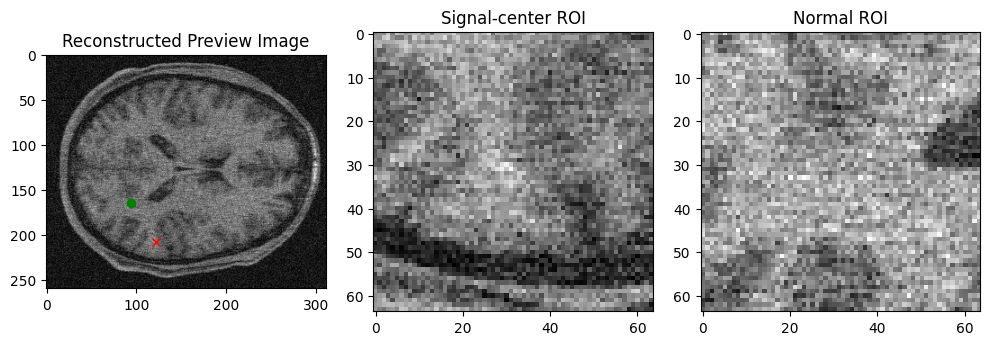

In [ ]:
image_i = 7 if len(selected_indices) > 7 else 0

signal_patch = signal_patches[image_i]
normal_patch = normal_patches[image_i]

present_images = load_reconstructed_images(
    source_mode,
    lesion_intensity,
    noise_level,
    undersampling_factor,
)
present_preview = np.asarray(present_images[selected_indices[image_i]], dtype=np.float32)

signal_index = images_lesion_indices[selected_indices[image_i]]
normal_index = images_normal_indices[selected_indices[image_i]]

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(present_preview, cmap='gray')
plt.plot(signal_index[1], signal_index[0], 'rx')
plt.plot(normal_index[1], normal_index[0], 'go')
plt.title('Reconstructed Preview Image')

plt.subplot(1, 3, 2)
plt.imshow(signal_patch, cmap='gray')
plt.title('Signal-center ROI')

plt.subplot(1, 3, 3)
plt.imshow(normal_patch, cmap='gray')
plt.title('Normal ROI')

plt.tight_layout()
plt.show()